**TASK1 - BUILD AND TRAIN AGAN MODEL USING TENSORFLOW**

In [ ]:
# ==========================================
# TASK 1: IMPORT REQUIRED LIBRARIES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

print("Libraries imported successfully")

TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Libraries imported successfully


In [ ]:
# ==========================================
# TASK 1: LOAD MNIST DATASET
# ==========================================

(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

print("Dataset Loaded Successfully")

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset Loaded Successfully
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Training Samples: 60000
Testing Samples: 10000


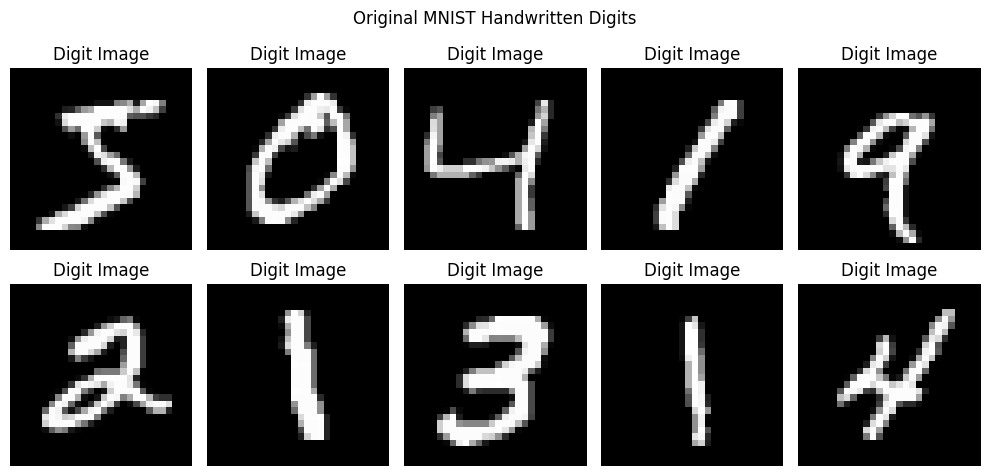

In [ ]:
# ==========================================
# TASK 1: DISPLAY ORIGINAL IMAGES
# ==========================================

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit Image")
    plt.axis('off')

plt.suptitle("Original MNIST Handwritten Digits")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# TASK 1: NORMALIZE DATASET
# ==========================================

x_train = (x_train.astype('float32') - 127.5) / 127.5

print("Normalization Completed")
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())
print("Data Type:", x_train.dtype)

Normalization Completed
Minimum Pixel Value: -1.0
Maximum Pixel Value: 1.0
Data Type: float32


In [ ]:
# ==========================================
# TASK 1: RESHAPE DATASET
# ==========================================

x_train = x_train.reshape(-1, 28, 28, 1)

print("Reshaping Completed")
print("Final Training Data Shape:", x_train.shape)

Reshaping Completed
Final Training Data Shape: (60000, 28, 28, 1)


In [ ]:
# ==========================================
# TASK 1: VERIFY PREPROCESSED DATASET
# ==========================================

print("Dataset Verification")
print("------------------------------")

print("Number of Images:", x_train.shape[0])
print("Image Height:", x_train.shape[1])
print("Image Width:", x_train.shape[2])
print("Channels:", x_train.shape[3])

print("Minimum Value:", x_train.min())
print("Maximum Value:", x_train.max())

print("Data Type:", x_train.dtype)

print("\nTask 1 completed successfully")

Dataset Verification
------------------------------
Number of Images: 60000
Image Height: 28
Image Width: 28
Channels: 1
Minimum Value: -1.0
Maximum Value: 1.0
Data Type: float32

Task 1 completed successfully


**TASK 2:NORMALIZE THE DATA**

In [ ]:
# ==========================================
# TASK 2: GENERATOR NETWORK IMPLEMENTATION
# IMPORT REQUIRED LIBRARIES
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

print("All libraries imported successfully")

TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
All libraries imported successfully


In [ ]:
# ==========================================
# DEFINE GENERATOR PARAMETERS
# ==========================================

noise_dim = 100
image_height = 28
image_width = 28
channels = 1

print("Generator Parameters")
print("------------------------------")
print("Noise Dimension:", noise_dim)
print("Image Height:", image_height)
print("Image Width:", image_width)
print("Channels:", channels)

print("Generator parameters defined successfully")

Generator Parameters
------------------------------
Noise Dimension: 100
Image Height: 28
Image Width: 28
Channels: 1
Generator parameters defined successfully


In [ ]:
# ==========================================
# BUILD GENERATOR NETWORK
# ==========================================

generator = tf.keras.Sequential([

    # Input Layer
    tf.keras.layers.Input(shape=(noise_dim,)),

    # Dense Layer
    tf.keras.layers.Dense(
        7 * 7 * 256,
        use_bias=False
    ),

    # Batch Normalization
    tf.keras.layers.BatchNormalization(),

    # Leaky ReLU Activation
    tf.keras.layers.LeakyReLU(alpha=0.2),

    # Reshape Layer
    tf.keras.layers.Reshape((7, 7, 256)),

    # Conv2DTranspose Layer 1
    tf.keras.layers.Conv2DTranspose(
        128,
        kernel_size=5,
        strides=1,
        padding='same',
        use_bias=False
    ),

    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(alpha=0.2),

    # Conv2DTranspose Layer 2
    tf.keras.layers.Conv2DTranspose(
        64,
        kernel_size=5,
        strides=2,
        padding='same',
        use_bias=False
    ),

    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(alpha=0.2),

    # Output Layer with Tanh Activation
    tf.keras.layers.Conv2DTranspose(
        1,
        kernel_size=5,
        strides=2,
        padding='same',
        activation='tanh'
    )

])

print("Generator Model Created Successfully")

Generator Model Created Successfully


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


In [ ]:
# ==========================================
# GENERATOR MODEL SUMMARY
# ==========================================

generator.summary()

print("Generator Model Summary Displayed Successfully")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

Generator Model Summary Displayed Successfully


In [ ]:
# ==========================================
# GENERATE RANDOM NOISE
# ==========================================

noise = tf.random.normal([1, noise_dim])

print("Random Noise Generated Successfully")
print("Noise Shape:", noise.shape)

print("Random noise generation completed")

Random Noise Generated Successfully
Noise Shape: (1, 100)
Random noise generation completed


In [ ]:
# ==========================================
# GENERATE FAKE IMAGE
# ==========================================

generated_image = generator(noise, training=False)

print("Generated Image Shape:", generated_image.shape)

print("Minimum Pixel Value:",
      tf.reduce_min(generated_image).numpy())

print("Maximum Pixel Value:",
      tf.reduce_max(generated_image).numpy())

print("Fake Image Generated Successfully")

Generated Image Shape: (1, 28, 28, 1)
Minimum Pixel Value: -0.06330624
Maximum Pixel Value: 0.07325277
Fake Image Generated Successfully


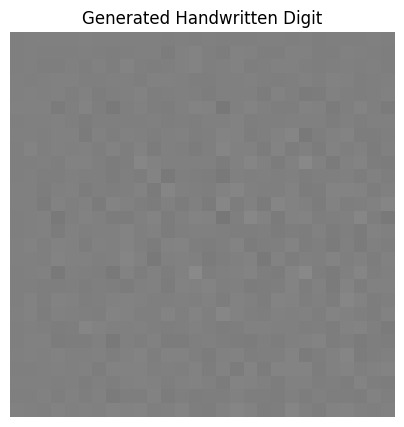

Generated Image Displayed Successfully


In [ ]:
# ==========================================
# DISPLAY GENERATED IMAGE
# ==========================================

plt.figure(figsize=(5, 5))

plt.imshow(
    generated_image[0, :, :, 0],
    cmap='gray',
    vmin=-1,
    vmax=1
)

plt.title("Generated Handwritten Digit")
plt.axis('off')

plt.show()

print("Generated Image Displayed Successfully")

In [ ]:
# ==========================================
# VERIFY ALL GENERATOR CONDITIONS
# ==========================================

# Check input shape
assert generator.input_shape == (None, 100)

# Check output shape
assert generator.output_shape == (None, 28, 28, 1)

# Check Dense layer
assert any(
    isinstance(layer, tf.keras.layers.Dense)
    for layer in generator.layers
)

# Check BatchNormalization
assert any(
    isinstance(layer, tf.keras.layers.BatchNormalization)
    for layer in generator.layers
)

# Check LeakyReLU
assert any(
    isinstance(layer, tf.keras.layers.LeakyReLU)
    for layer in generator.layers
)

# Check Conv2DTranspose
assert any(
    isinstance(layer, tf.keras.layers.Conv2DTranspose)
    for layer in generator.layers
)

# Check Tanh activation
assert generator.layers[-1].activation == tf.keras.activations.tanh

# Check generated image range
assert float(tf.reduce_min(generated_image)) >= -1.0
assert float(tf.reduce_max(generated_image)) <= 1.0

print("Generator Input Shape: Verified")
print("Generator Output Shape: Verified")
print("Dense Layer: Verified")
print("BatchNormalization: Verified")
print("LeakyReLU: Verified")
print("Conv2DTranspose: Verified")
print("Tanh Activation: Verified")
print("Generated Image Range: Verified")

print("--------------------------------------")
print("All Generator Conditions Satisfied")
print("Task 2 completed successfully")

Generator Input Shape: Verified
Generator Output Shape: Verified
Dense Layer: Verified
BatchNormalization: Verified
LeakyReLU: Verified
Conv2DTranspose: Verified
Tanh Activation: Verified
Generated Image Range: Verified
--------------------------------------
All Generator Conditions Satisfied
Task 2 completed successfully


**TASK 3:MODEL DESIGN GUIDELINES:**

In [ ]:
# ==========================================
# TASK 3: DISCRIMINATOR NETWORK
# IMPORT REQUIRED LIBRARIES
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

print("All libraries imported successfully")

TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
All libraries imported successfully


In [ ]:
# ==========================================
# DEFINE DISCRIMINATOR PARAMETERS
# ==========================================

image_height = 28
image_width = 28
channels = 1

learning_rate = 0.0002
beta_1 = 0.5

print("Discriminator Parameters")
print("--------------------------------")

print("Image Height:", image_height)
print("Image Width:", image_width)
print("Channels:", channels)
print("Learning Rate:", learning_rate)
print("Beta 1:", beta_1)

print("Discriminator parameters defined successfully")

Discriminator Parameters
--------------------------------
Image Height: 28
Image Width: 28
Channels: 1
Learning Rate: 0.0002
Beta 1: 0.5
Discriminator parameters defined successfully


In [ ]:
# ==========================================
# BUILD DISCRIMINATOR NETWORK
# ==========================================

discriminator = tf.keras.Sequential([

    # Input Layer
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First Convolution Layer
    tf.keras.layers.Conv2D(
        64,
        kernel_size=5,
        strides=2,
        padding='same'
    ),

    # Leaky ReLU Activation
    tf.keras.layers.LeakyReLU(negative_slope=0.2),

    # Dropout Layer
    tf.keras.layers.Dropout(0.3),

    # Second Convolution Layer
    tf.keras.layers.Conv2D(
        128,
        kernel_size=5,
        strides=2,
        padding='same'
    ),

    # Leaky ReLU Activation
    tf.keras.layers.LeakyReLU(negative_slope=0.2),

    # Dropout Layer
    tf.keras.layers.Dropout(0.3),

    # Flatten Layer
    tf.keras.layers.Flatten(),

    # Output Layer
    tf.keras.layers.Dense(
        1,
        activation='sigmoid'
    )

])

print("Discriminator Model Created Successfully")

Discriminator Model Created Successfully


In [ ]:
# ==========================================
# DISCRIMINATOR MODEL SUMMARY
# ==========================================

discriminator.summary()

print("Discriminator Model Summary Displayed Successfully")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Discriminator Model Summary Displayed Successfully


In [ ]:
# ==========================================
# COMPILE DISCRIMINATOR MODEL
# ==========================================

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator.compile(
    optimizer=discriminator_optimizer,
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

print("Discriminator Model Compiled Successfully")
print("Loss Function: Binary Cross-Entropy")
print("Optimizer: Adam")
print("Learning Rate: 0.0002")
print("Beta 1: 0.5")

Discriminator Model Compiled Successfully
Loss Function: Binary Cross-Entropy
Optimizer: Adam
Learning Rate: 0.0002
Beta 1: 0.5


In [ ]:
# ==========================================
# TEST DISCRIMINATOR WITH REAL IMAGES
# ==========================================

real_images = x_train[:5]

real_predictions = discriminator.predict(
    real_images,
    verbose=0
)

print("Real Image Predictions:")
print(real_predictions)

print("Real Images Shape:", real_images.shape)
print("Real Image Testing Completed Successfully")

Real Image Predictions:
[[0.47214246]
 [0.48601544]
 [0.49963233]
 [0.4654605 ]
 [0.47932875]]
Real Images Shape: (5, 28, 28, 1)
Real Image Testing Completed Successfully


In [ ]:
# ==========================================
# TEST DISCRIMINATOR WITH FAKE IMAGES
# ==========================================

noise = tf.random.normal([5, 100])

fake_images = generator(noise, training=False)

fake_predictions = discriminator.predict(
    fake_images,
    verbose=0
)

print("Fake Image Predictions:")
print(fake_predictions)

print("Fake Images Shape:", fake_images.shape)
print("Fake Image Testing Completed Successfully")

Fake Image Predictions:
[[0.49968272]
 [0.5004697 ]
 [0.50022566]
 [0.5000232 ]
 [0.4999452 ]]
Fake Images Shape: (5, 28, 28, 1)
Fake Image Testing Completed Successfully


In [ ]:
# ==========================================
# VERIFY ALL DISCRIMINATOR CONDITIONS
# ==========================================

# Check input shape
assert discriminator.input_shape == (None, 28, 28, 1)

# Check output shape
assert discriminator.output_shape == (None, 1)

# Check Conv2D layer
assert any(
    isinstance(layer, tf.keras.layers.Conv2D)
    for layer in discriminator.layers
)

# Check LeakyReLU layer
assert any(
    isinstance(layer, tf.keras.layers.LeakyReLU)
    for layer in discriminator.layers
)

# Check Dropout layer
assert any(
    isinstance(layer, tf.keras.layers.Dropout)
    for layer in discriminator.layers
)

# Check Flatten layer
assert any(
    isinstance(layer, tf.keras.layers.Flatten)
    for layer in discriminator.layers
)

# Check Dense layer
assert isinstance(
    discriminator.layers[-1],
    tf.keras.layers.Dense
)

# Check Sigmoid activation
assert discriminator.layers[-1].activation == tf.keras.activations.sigmoid

# Check prediction shapes
assert real_predictions.shape == (5, 1)
assert fake_predictions.shape == (5, 1)

# Check prediction range
assert np.all(real_predictions >= 0)
assert np.all(real_predictions <= 1)

assert np.all(fake_predictions >= 0)
assert np.all(fake_predictions <= 1)

print("Discriminator Input Shape: Verified")
print("Discriminator Output Shape: Verified")
print("Conv2D Layer: Verified")
print("LeakyReLU: Verified")
print("Dropout: Verified")
print("Flatten Layer: Verified")
print("Dense Layer: Verified")
print("Sigmoid Activation: Verified")
print("Binary Cross-Entropy Loss: Verified")
print("Adam Optimizer: Verified")
print("Real Image Testing: Verified")
print("Fake Image Testing: Verified")

print("--------------------------------------")
print("All Discriminator Conditions Satisfied")
print("Task 3 completed successfully")

Discriminator Input Shape: Verified
Discriminator Output Shape: Verified
Conv2D Layer: Verified
LeakyReLU: Verified
Dropout: Verified
Flatten Layer: Verified
Dense Layer: Verified
Sigmoid Activation: Verified
Binary Cross-Entropy Loss: Verified
Adam Optimizer: Verified
Real Image Testing: Verified
Fake Image Testing: Verified
--------------------------------------
All Discriminator Conditions Satisfied
Task 3 completed successfully


**TASK 4:OUTPUT REQUIREMENT:**

In [ ]:
# ==========================================
# TASK 4: GAN MODEL TRAINING
# IMPORT REQUIRED LIBRARIES
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

print("TensorFlow Version:", tf.__version__)
print("All training libraries imported successfully")

TensorFlow Version: 2.21.0
All training libraries imported successfully


In [ ]:
# ==========================================
# DEFINE GAN TRAINING PARAMETERS
# ==========================================

BUFFER_SIZE = 60000
BATCH_SIZE = 256
EPOCHS = 20
NOISE_DIM = 100

learning_rate = 0.0002
beta_1 = 0.5

print("GAN Training Parameters")
print("--------------------------------")

print("Buffer Size:", BUFFER_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Epochs:", EPOCHS)
print("Noise Dimension:", NOISE_DIM)
print("Learning Rate:", learning_rate)
print("Beta 1:", beta_1)

print("Training parameters defined successfully")

GAN Training Parameters
--------------------------------
Buffer Size: 60000
Batch Size: 256
Number of Epochs: 20
Noise Dimension: 100
Learning Rate: 0.0002
Beta 1: 0.5
Training parameters defined successfully


In [ ]:
# ==========================================
# PREPARE TRAINING DATASET
# ==========================================

train_dataset = tf.data.Dataset.from_tensor_slices(
    x_train
).shuffle(
    BUFFER_SIZE
).batch(
    BATCH_SIZE,
    drop_remainder=True
).prefetch(
    tf.data.AUTOTUNE
)

print("Training Dataset Prepared Successfully")
print("Training Images:", x_train.shape[0])
print("Batch Size:", BATCH_SIZE)
print("Number of Batches:", 234)

Training Dataset Prepared Successfully
Training Images: 60000
Batch Size: 256
Number of Batches: 234


In [ ]:
# ==========================================
# DEFINE LOSS FUNCTION AND OPTIMIZERS
# ==========================================

cross_entropy = tf.keras.losses.BinaryCrossentropy()

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

print("Loss Function: Binary Cross-Entropy")
print("Generator Optimizer: Adam")
print("Discriminator Optimizer: Adam")
print("Learning Rate: 0.0002")
print("Beta 1: 0.5")

print("Loss function and optimizers created successfully")

Loss Function: Binary Cross-Entropy
Generator Optimizer: Adam
Discriminator Optimizer: Adam
Learning Rate: 0.0002
Beta 1: 0.5
Loss function and optimizers created successfully


In [ ]:
# ==========================================
# DEFINE GENERATOR LOSS
# ==========================================

def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

print("Generator Loss Function Created Successfully")

Generator Loss Function Created Successfully


In [ ]:
# ==========================================
# DEFINE DISCRIMINATOR LOSS
# ==========================================

def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss

print("Discriminator Loss Function Created Successfully")

Discriminator Loss Function Created Successfully


In [ ]:
# ==========================================
# DEFINE GAN TRAINING FUNCTION
# ==========================================

@tf.function
def train_step(images):

    noise = tf.random.normal(
        [tf.shape(images)[0], NOISE_DIM]
    )

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        # Generate fake images
        generated_images = generator(
            noise,
            training=True
        )

        # Discriminator predictions
        real_output = discriminator(
            images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        # Calculate losses
        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update Generator
    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )

    # Update Discriminator
    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

print("GAN Training Function Created Successfully")

GAN Training Function Created Successfully


In [ ]:
# ==========================================
# GENERATE SAMPLE IMAGES
# ==========================================

fixed_noise = tf.random.normal([16, NOISE_DIM])

def generate_and_save_images(model, epoch):

    predictions = model(
        fixed_noise,
        training=False
    )

    predictions = (predictions + 1) / 2

    plt.figure(figsize=(8, 8))

    for i in range(16):

        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0],
            cmap='gray'
        )

        plt.axis('off')

    plt.suptitle(
        f"Generated Images - Epoch {epoch}"
    )

    plt.tight_layout()
    plt.show()

print("Image Generation Function Created Successfully")

Image Generation Function Created Successfully


Starting GAN Training...
--------------------------------
Epoch 1/20 | Generator Loss: 0.6794 | Discriminator Loss: 1.2877
Epoch 2/20 | Generator Loss: 0.7474 | Discriminator Loss: 1.3309
Epoch 3/20 | Generator Loss: 0.7480 | Discriminator Loss: 1.3250
Epoch 4/20 | Generator Loss: 0.7724 | Discriminator Loss: 1.3151
Epoch 5/20 | Generator Loss: 0.7927 | Discriminator Loss: 1.2955


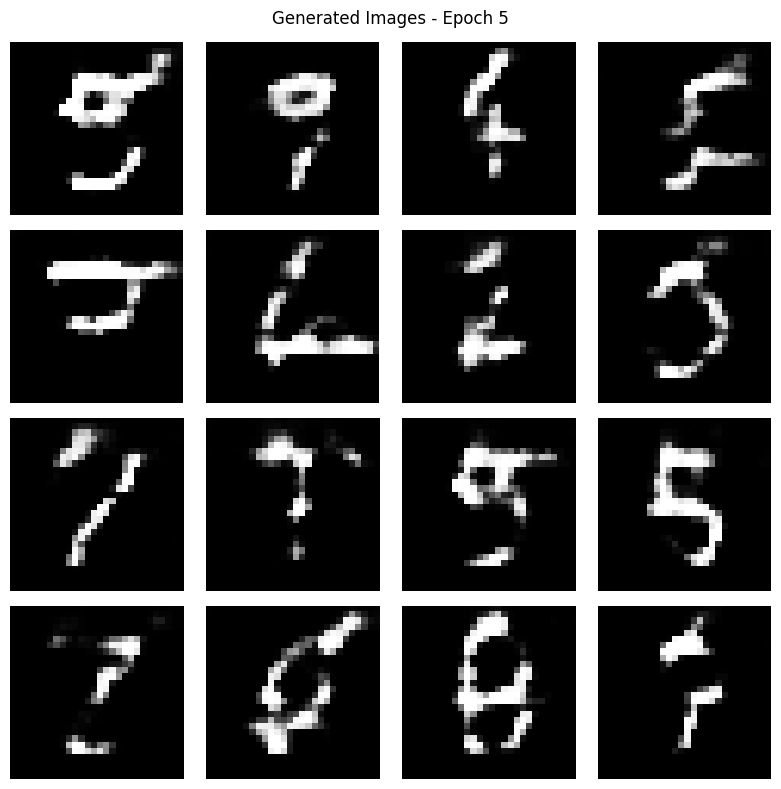

Epoch 6/20 | Generator Loss: 0.7652 | Discriminator Loss: 1.3258
Epoch 7/20 | Generator Loss: 0.7698 | Discriminator Loss: 1.3325
Epoch 8/20 | Generator Loss: 0.7478 | Discriminator Loss: 1.3437
Epoch 9/20 | Generator Loss: 0.7564 | Discriminator Loss: 1.3374
Epoch 10/20 | Generator Loss: 0.7487 | Discriminator Loss: 1.3401


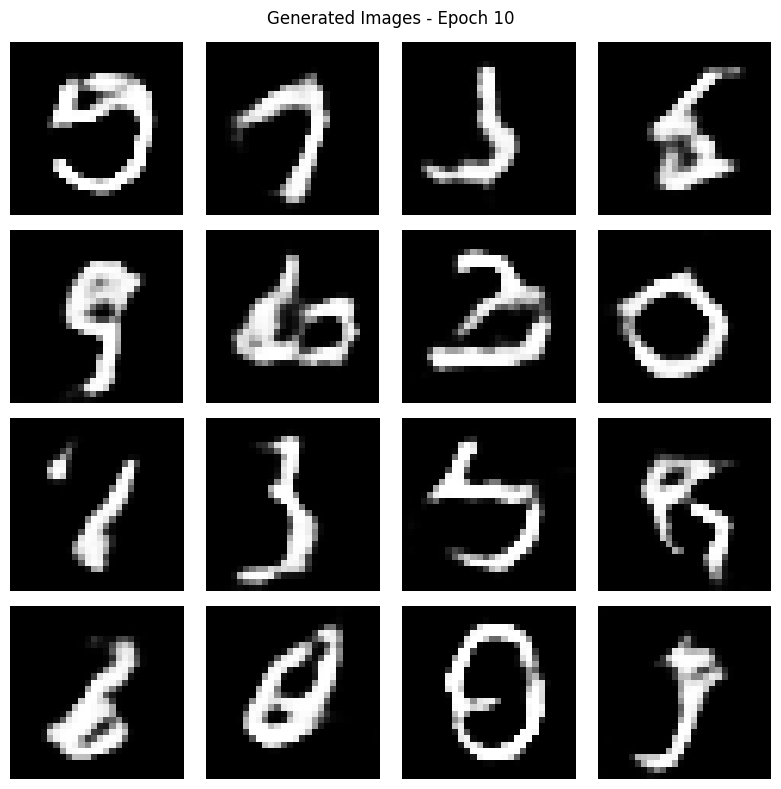

Epoch 11/20 | Generator Loss: 0.7554 | Discriminator Loss: 1.3342
Epoch 12/20 | Generator Loss: 0.7577 | Discriminator Loss: 1.3315
Epoch 13/20 | Generator Loss: 0.7643 | Discriminator Loss: 1.3274
Epoch 14/20 | Generator Loss: 0.7680 | Discriminator Loss: 1.3234
Epoch 15/20 | Generator Loss: 0.7768 | Discriminator Loss: 1.3173


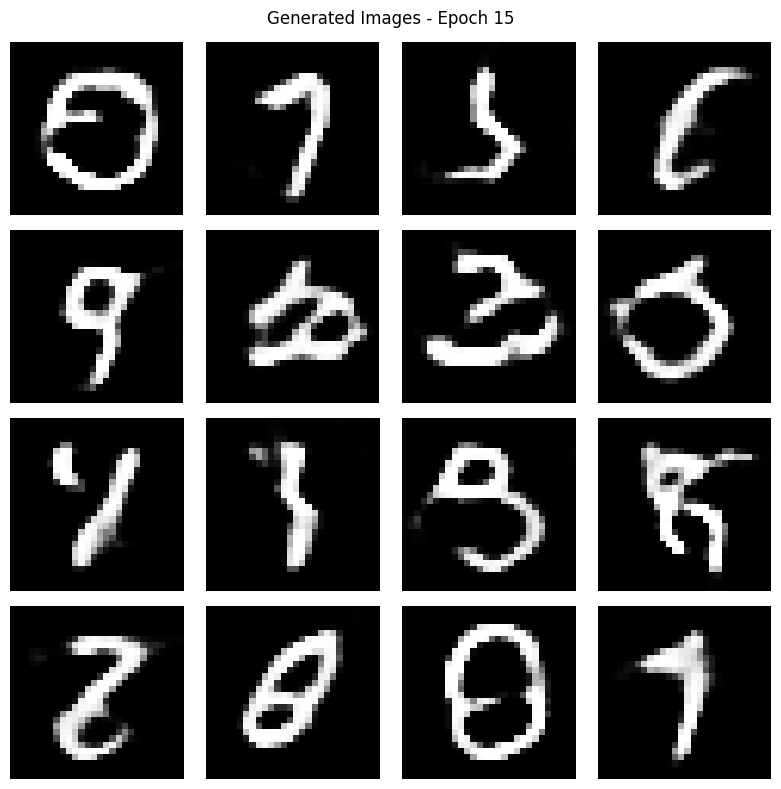

Epoch 16/20 | Generator Loss: 0.7709 | Discriminator Loss: 1.3196
Epoch 17/20 | Generator Loss: 0.7852 | Discriminator Loss: 1.3098
Epoch 18/20 | Generator Loss: 0.7848 | Discriminator Loss: 1.3082
Epoch 19/20 | Generator Loss: 0.7923 | Discriminator Loss: 1.3036
Epoch 20/20 | Generator Loss: 0.7920 | Discriminator Loss: 1.3061


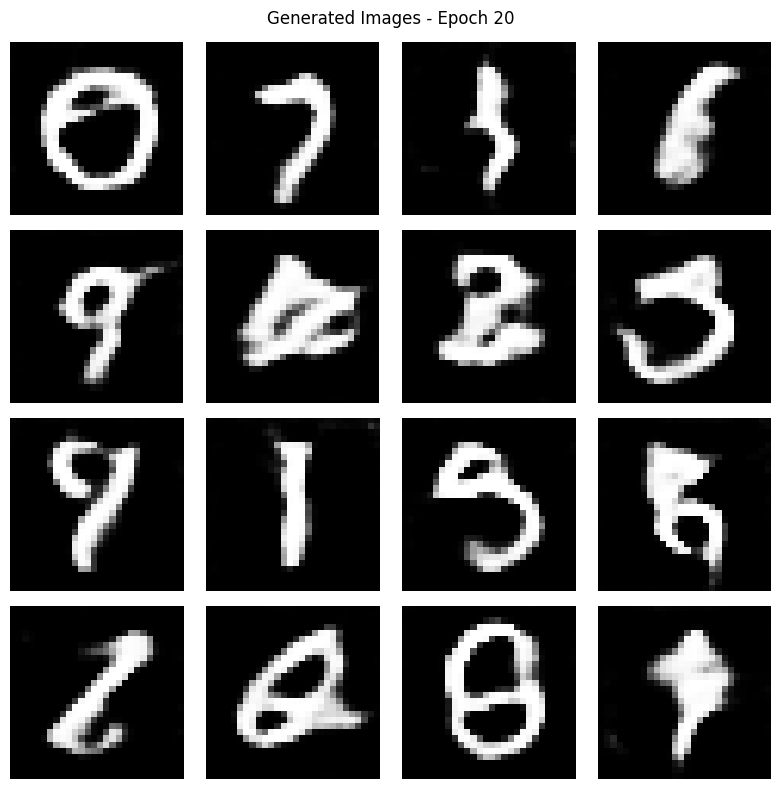

--------------------------------
Total Training Time: 10027.78 seconds
GAN Training Completed Successfully


In [ ]:
# ==========================================
# TRAIN GAN MODEL FOR 20 EPOCHS
# ==========================================

generator_losses = []
discriminator_losses = []

print("Starting GAN Training...")
print("--------------------------------")

start_time = time.time()

for epoch in range(EPOCHS):

    total_gen_loss = 0.0
    total_disc_loss = 0.0
    batch_count = 0

    for image_batch in train_dataset:

        gen_loss, disc_loss = train_step(image_batch)

        total_gen_loss += float(gen_loss.numpy())
        total_disc_loss += float(disc_loss.numpy())

        batch_count += 1

    # Calculate average losses
    avg_gen_loss = total_gen_loss / batch_count
    avg_disc_loss = total_disc_loss / batch_count

    generator_losses.append(avg_gen_loss)
    discriminator_losses.append(avg_disc_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {avg_gen_loss:.4f} | "
        f"Discriminator Loss: {avg_disc_loss:.4f}"
    )

    # Display images every 5 epochs
    if (epoch + 1) % 5 == 0:
        generate_and_save_images(
            generator,
            epoch + 1
        )

end_time = time.time()

print("--------------------------------")
print("Total Training Time:",
      round(end_time - start_time, 2), "seconds")

print("GAN Training Completed Successfully")

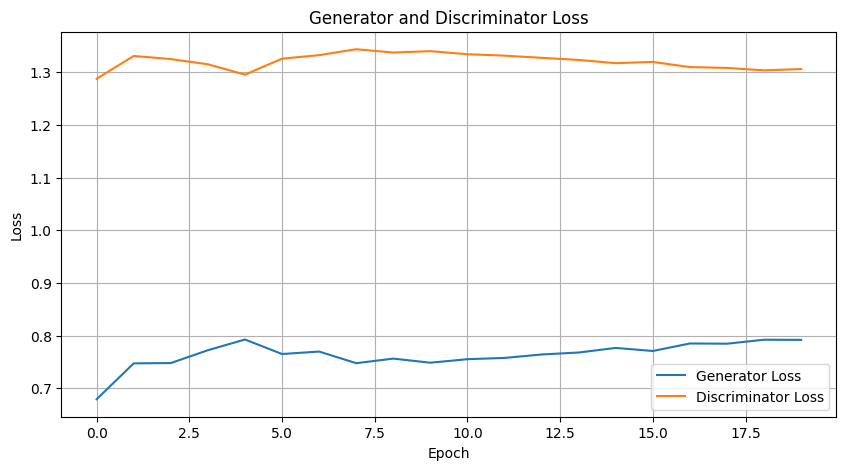

GAN Loss Curves Displayed Successfully


In [ ]:
# ==========================================
# PLOT GAN LOSS CURVES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    generator_losses,
    label='Generator Loss'
)

plt.plot(
    discriminator_losses,
    label='Discriminator Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Generator and Discriminator Loss")

plt.legend()
plt.grid(True)

plt.show()

print("GAN Loss Curves Displayed Successfully")

In [ ]:
# ==========================================
# VERIFY GAN TRAINING RESULTS
# ==========================================

assert len(generator_losses) == EPOCHS

assert len(discriminator_losses) == EPOCHS

assert np.all(np.isfinite(generator_losses))

assert np.all(np.isfinite(discriminator_losses))

assert generator.trainable_variables

assert discriminator.trainable_variables

print("Generator Training: Verified")
print("Discriminator Training: Verified")
print("Generator Loss History: Verified")
print("Discriminator Loss History: Verified")
print("Training Epochs:", len(generator_losses))
print("Training Batches Per Epoch:", 234)

print("--------------------------------------")
print("All GAN Training Conditions Satisfied")
print("Task 4 completed successfully")

Generator Training: Verified
Discriminator Training: Verified
Generator Loss History: Verified
Discriminator Loss History: Verified
Training Epochs: 20
Training Batches Per Epoch: 234
--------------------------------------
All GAN Training Conditions Satisfied
Task 4 completed successfully


**TASK -5:IMAGE GENERATION AND EVALUATION.**

In [ ]:
# ==========================================
# TASK 5: IMAGE GENERATION AND EVALUATION
# IMPORT REQUIRED LIBRARIES
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow Version:", tf.__version__)
print("All libraries imported successfully")

TensorFlow Version: 2.21.0
All libraries imported successfully


In [ ]:
# ==========================================
# CREATE OUTPUT FOLDER
# ==========================================

output_folder = "GAN_Results"

os.makedirs(output_folder, exist_ok=True)

print("Output Folder Created Successfully")
print("Folder Name:", output_folder)

Output Folder Created Successfully
Folder Name: GAN_Results


In [ ]:
# ==========================================
# GENERATE RANDOM NOISE
# ==========================================

noise_dim = 100
num_images = 25

random_noise = tf.random.normal(
    [num_images, noise_dim]
)

print("Random Noise Generated Successfully")
print("Noise Shape:", random_noise.shape)
print("Number of Images:", num_images)

Random Noise Generated Successfully
Noise Shape: (25, 100)
Number of Images: 25


In [ ]:
# ==========================================
# GENERATE HANDWRITTEN DIGIT IMAGES
# ==========================================

generated_images = generator(
    random_noise,
    training=False
)

print("Generated Images Shape:", generated_images.shape)

print("Minimum Pixel Value:",
      float(tf.reduce_min(generated_images)))

print("Maximum Pixel Value:",
      float(tf.reduce_max(generated_images)))

print("Handwritten Digit Images Generated Successfully")

Generated Images Shape: (25, 28, 28, 1)
Minimum Pixel Value: -1.0
Maximum Pixel Value: 0.9999967217445374
Handwritten Digit Images Generated Successfully


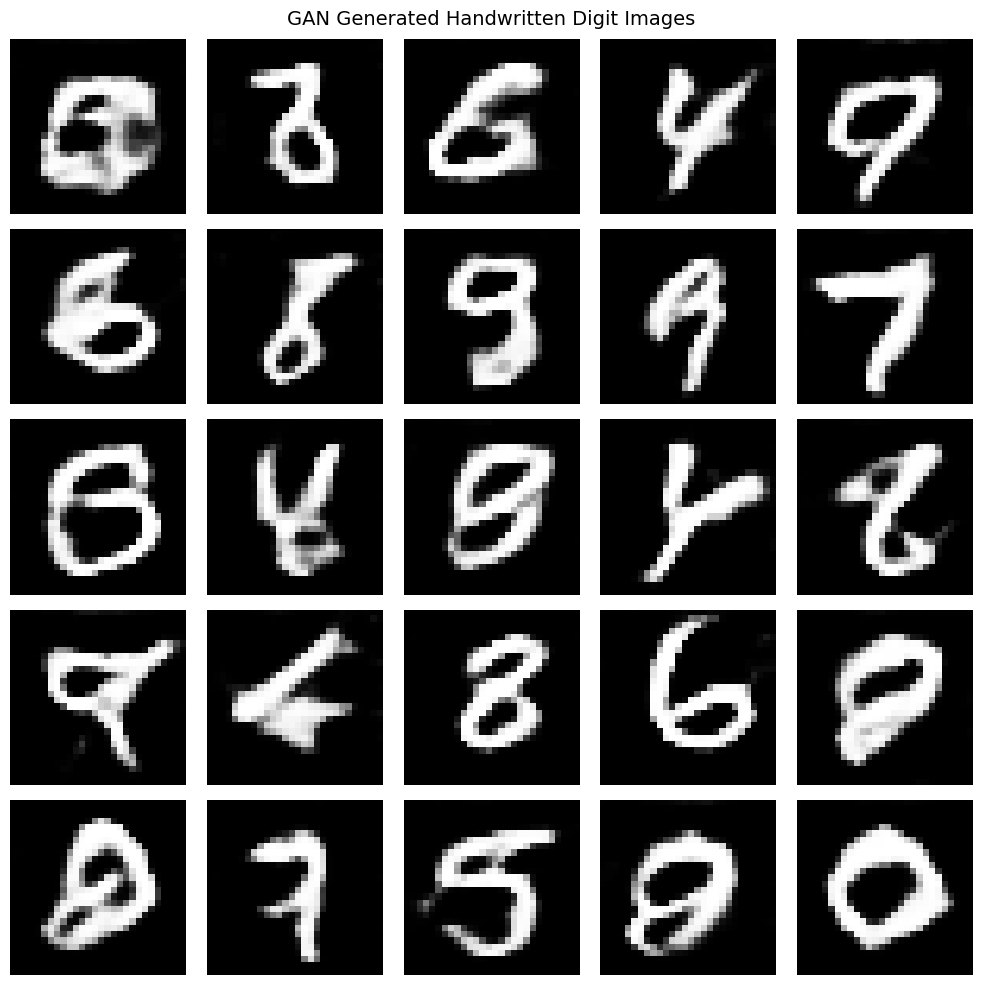

Generated Image Grid Displayed Successfully


In [ ]:
# ==========================================
# DISPLAY GENERATED DIGIT IMAGE GRID
# ==========================================

images = (generated_images + 1) / 2

plt.figure(figsize=(10, 10))

for i in range(num_images):

    plt.subplot(5, 5, i + 1)

    plt.imshow(
        images[i, :, :, 0],
        cmap='gray'
    )

    plt.axis('off')

plt.suptitle(
    "GAN Generated Handwritten Digit Images",
    fontsize=14
)

plt.tight_layout()

plt.show()

print("Generated Image Grid Displayed Successfully")

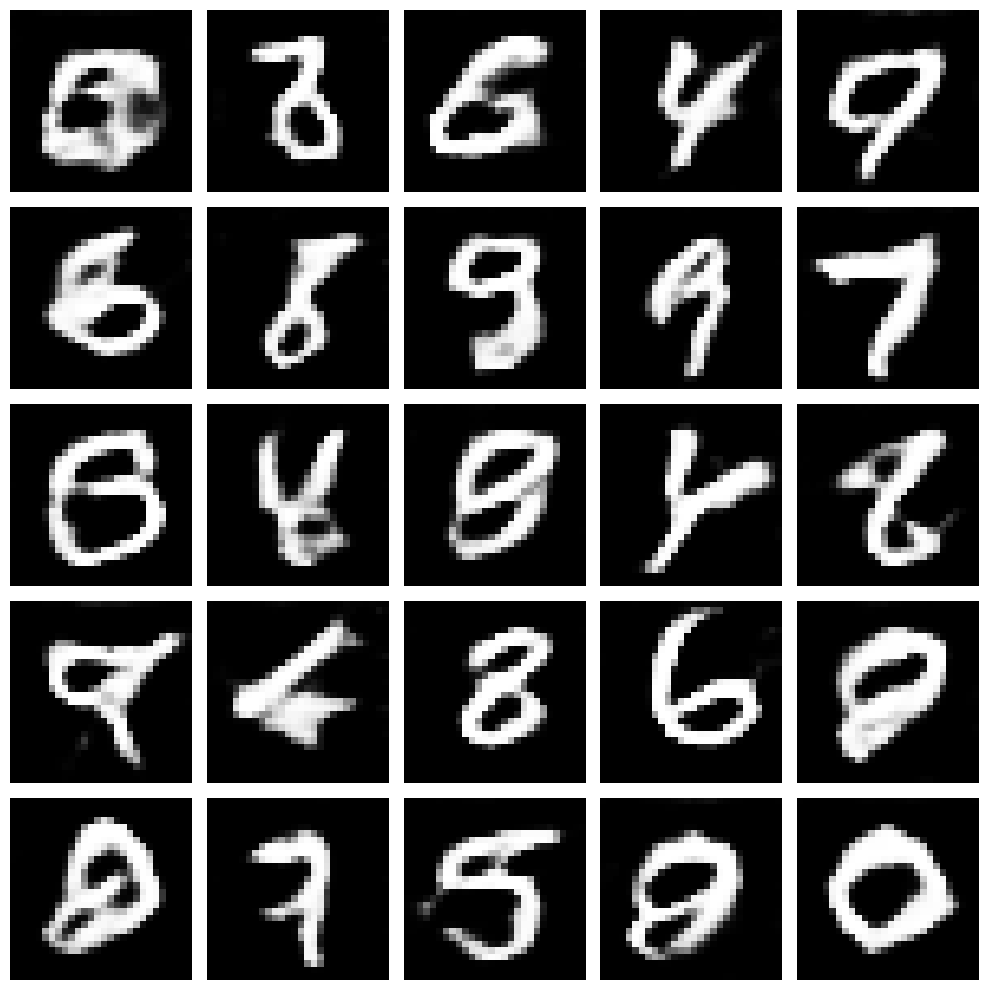

Generated Images Saved Successfully
File Name: GAN_Results/generated_digits.png


In [ ]:
# ==========================================
# SAVE GENERATED DIGIT IMAGE GRID
# ==========================================

plt.figure(figsize=(10, 10))

for i in range(num_images):

    plt.subplot(5, 5, i + 1)

    plt.imshow(
        images[i, :, :, 0],
        cmap='gray'
    )

    plt.axis('off')

plt.tight_layout()

image_path = os.path.join(
    output_folder,
    "generated_digits.png"
)

plt.savefig(
    image_path,
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print("Generated Images Saved Successfully")
print("File Name:", image_path)

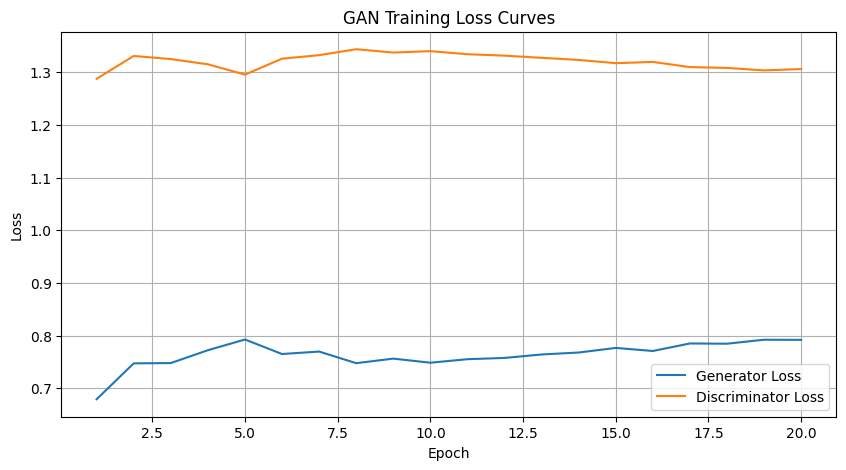

Generator Loss: 0.7920489097252871
Discriminator Loss: 1.3060831998148534
GAN Loss Curves Saved Successfully


In [ ]:
# ==========================================
# PLOT GENERATOR AND DISCRIMINATOR LOSS
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(generator_losses) + 1),
    generator_losses,
    label='Generator Loss'
)

plt.plot(
    range(1, len(discriminator_losses) + 1),
    discriminator_losses,
    label='Discriminator Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("GAN Training Loss Curves")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(output_folder, "gan_loss_curves.png"),
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print("Generator Loss:", generator_losses[-1])
print("Discriminator Loss:", discriminator_losses[-1])

print("GAN Loss Curves Saved Successfully")

In [ ]:
# ==========================================
# EVALUATE GENERATED IMAGES
# ==========================================

predictions = discriminator.predict(
    generated_images,
    verbose=0
)

print("Generated Image Evaluation")
print("--------------------------------")

print("Number of Images Evaluated:", len(predictions))

print("Average Real Probability:",
      np.mean(predictions))

print("Average Fake Probability:",
      1 - np.mean(predictions))

print("Minimum Prediction:", predictions.min())
print("Maximum Prediction:", predictions.max())

print("Image Evaluation Completed Successfully")

Generated Image Evaluation
--------------------------------
Number of Images Evaluated: 25
Average Real Probability: 0.42946354
Average Fake Probability: 0.5705365
Minimum Prediction: 0.278155
Maximum Prediction: 0.54381233
Image Evaluation Completed Successfully
